# Monitoring and Logging a Deployed Loan Default Model

In this practice you will add logging to a loan default model, log every call to a FastAPI prediction endpoint, track the model's accuracy over time, and run a simple drift check on incoming data.

Everything here uses only what Lesson 6 covers: logging levels, logging in FastAPI, monitoring model performance and detecting data drift.

## Background

A bank has deployed a logistic regression model, the same one trained in Lesson 5, that predicts whether a loan applicant will default. The bank now needs to know whether the model is still reliable as new applications arrive each month.

This practice uses **BANK LOAN.csv**, the dataset from Lesson 5.

**Before you start:** FastAPI and its test client are needed for Section 4. Install them with `pip install fastapi httpx`.

## Data Description

| Column Name | Description |
|---|---|
| SN | Serial number (identifier only) |
| AGE | Age group code |
| EMPLOY | Number of years with current employer |
| ADDRESS | Number of years at current address |
| DEBTINC | Debt to income ratio |
| CREDDEBT | Credit card debt |
| OTHDEBT | Other debt |
| DEFAULTER | **Target variable:** 1 = defaulted, 0 = did not default |

## 1. Train the Deployed Model

We repeat the Lesson 5 training step: drop the identifier, split the data and fit a logistic regression.

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

loans = pd.read_csv("BANK LOAN.csv").drop(columns=["SN"])
features = ["AGE", "EMPLOY", "ADDRESS", "DEBTINC", "CREDDEBT", "OTHDEBT"]

X = loans[features]
y = loans["DEFAULTER"]

X_train, X_new, y_train, y_new = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y)

model = LogisticRegression(max_iter=500)
model.fit(X_train, y_train)

print("Training rows:", len(X_train), "| Rows held back as new applications:", len(X_new))

Training rows: 420 | Rows held back as new applications: 280


## 2. Set Up Logging

Python's built-in `logging` module records events at different severity levels: **INFO** for normal events, **WARNING** for unexpected but non-critical issues, and **ERROR** for failures. Logs are written to a `.log` file for later review.

In [2]:
import logging

logger = logging.getLogger("loan_model")
logger.setLevel(logging.INFO)
logger.handlers.clear()

handler = logging.FileHandler("app.log", mode="w")
handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
logger.addHandler(handler)

logger.info("Loan default model loaded")

## 3. Log Every Prediction

A prediction function records the request, the input received, the prediction returned and the response time. If an input is missing a feature, it logs an error instead of failing silently.

In [3]:
import time

def predict_default(applicant: dict):
    start = time.perf_counter()
    missing = [f for f in features if f not in applicant]
    if missing:
        logger.error(f"Prediction failed, missing features: {missing}")
        return None

    row = pd.DataFrame([applicant])[features]
    probability = model.predict_proba(row)[0, 1]
    prediction = "Default" if probability >= 0.5 else "No default"
    elapsed_ms = (time.perf_counter() - start) * 1000

    logger.info(f"Input: {applicant} | Prediction: {prediction} "
                f"(p={probability:.2f}) | Response time: {elapsed_ms:.1f}ms")
    if probability >= 0.9:
        logger.warning(f"Very high default probability ({probability:.2f}), refer for review")
    return prediction

In [4]:
print(predict_default({"AGE": 2, "EMPLOY": 10, "ADDRESS": 7,
                       "DEBTINC": 8.5, "CREDDEBT": 0.9, "OTHDEBT": 2.1}))
print(predict_default({"AGE": 1, "EMPLOY": 0, "ADDRESS": 1,
                       "DEBTINC": 35.0, "CREDDEBT": 9.0, "OTHDEBT": 12.0}))
print(predict_default({"AGE": 2, "EMPLOY": 5}))

No default
Default
None


## 4. Log Calls to a FastAPI Endpoint

In production, the model sits behind an API. Here a FastAPI endpoint logs every call. FastAPI's `TestClient` lets us call the endpoint from the notebook without starting a server.

In [5]:
from fastapi import FastAPI
from fastapi.testclient import TestClient
from pydantic import BaseModel

class Applicant(BaseModel):
    AGE: int
    EMPLOY: int
    ADDRESS: int
    DEBTINC: float
    CREDDEBT: float
    OTHDEBT: float

app = FastAPI()

@app.post("/predict")
def predict(applicant: Applicant):
    logger.info("Prediction endpoint called")
    return {"prediction": predict_default(applicant.model_dump())}

client = TestClient(app)
response = client.post("/predict", json={"AGE": 3, "EMPLOY": 15, "ADDRESS": 12,
                                         "DEBTINC": 6.0, "CREDDEBT": 0.5, "OTHDEBT": 1.2})
print(response.status_code, response.json())

200 {'prediction': 'No default'}


## 5. Read the Log

Logging feeds monitoring: you cannot monitor what you have not logged. Here is the full audit trail so far.

In [6]:
handler.flush()
with open("app.log") as f:
    print(f.read())

2026-10-19 13:50:42,713 | INFO | Loan default model loaded
2026-10-19 13:50:42,751 | INFO | Input: {'AGE': 2, 'EMPLOY': 10, 'ADDRESS': 7, 'DEBTINC': 8.5, 'CREDDEBT': 0.9, 'OTHDEBT': 2.1} | Prediction: No default (p=0.08) | Response time: 3.8ms
2026-10-19 13:50:42,754 | INFO | Input: {'AGE': 1, 'EMPLOY': 0, 'ADDRESS': 1, 'DEBTINC': 35.0, 'CREDDEBT': 9.0, 'OTHDEBT': 12.0} | Prediction: Default (p=1.00) | Response time: 2.5ms
2026-10-19 13:50:42,754 | WARNING | Very high default probability (1.00), refer for review
2026-10-19 13:50:42,755 | ERROR | Prediction failed, missing features: ['ADDRESS', 'DEBTINC', 'CREDDEBT', 'OTHDEBT']
2026-10-19 13:50:43,200 | INFO | Prediction endpoint called
2026-10-19 13:50:43,204 | INFO | Input: {'AGE': 3, 'EMPLOY': 15, 'ADDRESS': 12, 'DEBTINC': 6.0, 'CREDDEBT': 0.5, 'OTHDEBT': 1.2} | Prediction: No default (p=0.01) | Response time: 4.0ms



## 6. Simulate Four Months of New Applications

To monitor the model, we need new data over time. We split the held-back applications into four monthly batches. In months 3 and 4 the bank starts a campaign that attracts more highly indebted applicants, so we draw those batches mainly from applicants with a high debt to income ratio. (Batches are sampled from the same pool, so they may share applicants.) This changes the input distribution: **data drift**.

In [7]:
new = X_new.copy()
new["DEFAULTER"] = y_new.values
high_debt = new["DEBTINC"] > new["DEBTINC"].median()

months = {
    "Month 1": new.sample(60, random_state=1),
    "Month 2": new.sample(60, random_state=2),
    "Month 3": pd.concat([new[high_debt].sample(45, random_state=3), new[~high_debt].sample(15, random_state=3)]),
    "Month 4": pd.concat([new[high_debt].sample(50, random_state=4), new[~high_debt].sample(10, random_state=4)]),
}
{m: len(b) for m, b in months.items()}

{'Month 1': 60, 'Month 2': 60, 'Month 3': 60, 'Month 4': 60}

## 7. Monitor Performance Over Time

When the true outcomes become known, we compare predictions with actual values each month. A single snapshot is not enough: the trend reveals degradation.

In [8]:
from sklearn.metrics import accuracy_score

monitor = []
for month, batch in months.items():
    preds = model.predict(batch[features])
    monitor.append({"month": month,
                    "accuracy": accuracy_score(batch["DEFAULTER"], preds),
                    "share predicted default": preds.mean(),
                    "actual default rate": batch["DEFAULTER"].mean()})

monitor = pd.DataFrame(monitor).round(3)
monitor

,month,accuracy,share predicted default,actual default rate
0,Month 1,0.783,0.267,0.283
1,Month 2,0.867,0.183,0.250
2,Month 3,0.800,0.367,0.367
3,Month 4,0.833,0.317,0.250


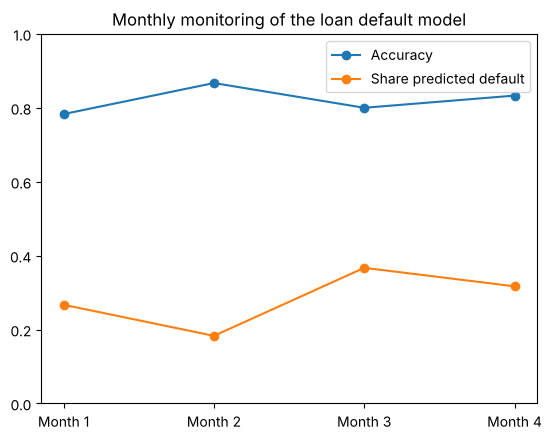

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.plot(monitor["month"], monitor["accuracy"], marker="o", label="Accuracy")
ax.plot(monitor["month"], monitor["share predicted default"], marker="o", label="Share predicted default")
ax.set_ylim(0, 1)
ax.set_title("Monthly monitoring of the loan default model")
ax.legend()
plt.show()

In this simulation, accuracy holds up, but the share of applicants predicted to default rises in months 3 and 4. Drift does not always reduce accuracy straight away, and in lending the true outcomes may not be known for months. That is why monitoring tracks the inputs and the prediction distribution as well as accuracy: they give an earlier warning.

## 8. Detect Data Drift

The lesson's simple check compares the mean of each feature in the training data with its mean in new data, and flags drift when the difference is larger than a threshold. Here the threshold is half of the training standard deviation.

In [10]:
def check_drift(train, batch, threshold_sd=0.5, log=True):
    rows = []
    for col in features:
        train_mean, new_mean = train[col].mean(), batch[col].mean()
        threshold = threshold_sd * train[col].std()
        drift = abs(train_mean - new_mean) > threshold
        rows.append({"feature": col, "train mean": train_mean, "new mean": new_mean,
                     "threshold": threshold, "drift": drift})
        if drift and log:
            logger.warning(f"Data drift detected in {col}: train mean {train_mean:.2f}, new mean {new_mean:.2f}")
    return pd.DataFrame(rows).round(2)

for month, batch in months.items():
    result = check_drift(X_train, batch)
    flagged = result.loc[result["drift"], "feature"].tolist()
    print(f"{month}: drift in {flagged if flagged else 'no features'}")

Month 1: drift in no features
Month 2: drift in no features
Month 3: drift in ['DEBTINC', 'OTHDEBT']
Month 4: drift in ['DEBTINC', 'OTHDEBT']


Here is the full check for month 4. It is already logged, so we switch logging off for this display.

In [11]:
check_drift(X_train, months["Month 4"], log=False)

,feature,train mean,new mean,threshold,drift
0,AGE,1.87,1.85,0.38,False
1,EMPLOY,8.25,9.00,3.35,False
2,ADDRESS,8.25,7.93,3.43,False
3,DEBTINC,9.76,14.84,3.33,True
4,CREDDEBT,1.44,2.16,1.03,False
5,OTHDEBT,2.84,4.48,1.52,True


The check flags drift in months 3 and 4, in line with the campaign. The drift warnings are now in the log file too, ready to feed an alert.

This mean-based check is a starting point. Production systems use dedicated tools such as **Evidently AI** for multi-feature drift analysis, with **Prometheus** and **Grafana** for metrics and dashboards.

In [12]:
handler.flush()
with open("app.log") as f:
    print("".join(line for line in f if "WARNING" in line))

2026-10-19 13:50:42,754 | WARNING | Very high default probability (1.00), refer for review
2026-10-19 13:50:44,005 | WARNING | Data drift detected in DEBTINC: train mean 9.76, new mean 13.54
2026-10-19 13:50:44,006 | WARNING | Data drift detected in OTHDEBT: train mean 2.84, new mean 4.56
2026-10-19 13:50:44,009 | WARNING | Data drift detected in DEBTINC: train mean 9.76, new mean 14.84
2026-10-19 13:50:44,009 | WARNING | Data drift detected in OTHDEBT: train mean 2.84, new mean 4.48



## Summary

- Logging records requests, inputs, predictions, response times and errors at INFO, WARNING and ERROR levels.
- FastAPI endpoints can log every call, giving a full audit trail.
- Monitoring tracks model performance and the prediction distribution over time, not just once.
- A simple mean-based check can flag data drift; dedicated tools extend this in production.
- Logging feeds monitoring: you cannot monitor what you have not logged.